In [2]:
!pip install autogen
!pip install yfinance matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 33.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [autogen]


In [3]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import datetime
import getpass

from autogen import ConversableAgent, AssistantAgent
from autogen.coding import LocalCommandLineCodeExecutor

In [17]:
# ============================================================
# 2. CONFIGURE NVIDIA API
# ============================================================

# Enter your NVIDIA API key securely
nvidia_api_key = getpass.getpass("Enter your NVIDIA API key: ")

os.environ["NVIDIA_API_KEY"] = nvidia_api_key

# NVIDIA OpenAI-compatible API configuration
llm_config = {
    "config_list": [
        {
            "model": "nvidia/nemotron-3.5-lightning-30b-a3b",
            "api_key": os.environ["NVIDIA_API_KEY"],
            "base_url": "https://integrate.api.nvidia.com/v1"
        }
    ],
    "temperature": 0.1,
    "timeout": 180,
    "cache_seed": None
}

print("NVIDIA API configuration completed!")


Enter your NVIDIA API key: ··········
NVIDIA API configuration completed!


In [18]:

# ============================================================
# 3. CREATE LOCAL CODE EXECUTOR
# ============================================================

executor = LocalCommandLineCodeExecutor(
    work_dir="coding",
    timeout=180
)


In [19]:

# ============================================================
# 4. CREATE CODE EXECUTOR AGENT
# ============================================================

code_executor_agent = ConversableAgent(
    name="code_executor_agent",

    llm_config=False,

    code_execution_config={
        "executor": executor
    },

    human_input_mode="NEVER",

    max_consecutive_auto_reply=5,

    default_auto_reply=(
        "Please examine the execution results. "
        "If the task is complete, reply TERMINATE."
    )
)


In [20]:
# ============================================================
# 5. CREATE CODE WRITER AGENT
# ============================================================

code_writer_agent = AssistantAgent(
    name="code_writer_agent",

    llm_config=llm_config,

    code_execution_config=False,

    human_input_mode="NEVER",

    system_message="""
    You are an expert Python programmer and financial data analyst.

    Your responsibilities are:

    1. Generate clean and executable Python code.
    2. Use yfinance to retrieve stock market data.
    3. Calculate year-to-date (YTD) stock returns.
    4. Create meaningful visualizations using matplotlib.
    5. Save the generated figure to the requested file.
    6. Present the complete Python code inside a Markdown code block.

    IMPORTANT:
    - Use actual stock market data.
    - Never fabricate stock prices or returns.
    - Handle missing data and download errors.
    - Make sure the Python code is executable in Google Colab.
    - After successful execution, clearly report the output filename.
    """
)


In [21]:
# ============================================================
# 6. PREPARE STOCK ANALYSIS TASK
# ============================================================

today = datetime.datetime.now().date()

message = f"""
Today is {today}.

TASK: STOCK MARKET YTD PERFORMANCE ANALYSIS

Analyze the year-to-date stock returns of:

1. Tata Elxsi (NSE: TATAELXSI.NS)
2. Infosys (NSE: INFY.NS)

Instructions:

1. Use yfinance to download actual historical stock price data.
2. Calculate YTD percentage returns using the first available
   trading day's closing price in the current calendar year
   as the baseline.
3. Use the latest available closing price as the ending price.
4. Calculate:

   YTD Return (%) =
   ((Latest Price - Starting Price) / Starting Price) * 100

5. Create a professional matplotlib bar chart comparing
   the YTD returns of both companies.
6. Display the percentage values on the chart.
7. Include a suitable title, axis labels, legend if needed,
   and grid lines.
8. Save the chart as:

   ytd_stock_gains.png

9. Save the figure in the current working directory.

IMPORTANT:
First generate the complete Python code in a Markdown code block.
Then execute the code and inspect the output.
If errors occur, correct them and execute again.
"""


In [22]:


# ============================================================
# 7. INITIATE COLLABORATION BETWEEN THE TWO AGENTS
# ============================================================

chat_result = code_executor_agent.initiate_chat(
    code_writer_agent,
    message=message,
    summary_method="last_msg"
)


code_executor_agent (to code_writer_agent):


Today is 2026-10-30.

TASK: STOCK MARKET YTD PERFORMANCE ANALYSIS

Analyze the year-to-date stock returns of:

1. Tata Elxsi (NSE: TATAELXSI.NS)
2. Infosys (NSE: INFY.NS)

Instructions:

1. Use yfinance to download actual historical stock price data.
2. Calculate YTD percentage returns using the first available
   trading day's closing price in the current calendar year
   as the baseline.
3. Use the latest available closing price as the ending price.
4. Calculate:

   YTD Return (%) =
   ((Latest Price - Starting Price) / Starting Price) * 100

5. Create a professional matplotlib bar chart comparing
   the YTD returns of both companies.
6. Display the percentage values on the chart.
7. Include a suitable title, axis labels, legend if needed,
   and grid lines.
8. Save the chart as:

   ytd_stock_gains.png

9. Save the figure in the current working directory.

IMPORTANT:
First generate the complete Python code in a Markdown code block.
Then

code_writer_agent (to code_executor_agent):

**Python Code (Executable in Colab/Script):**

```python
import yfinance as yf
import matplotlib.pyplot as plt

# NSE tickers for Tata Elxsi and Infosys
tickers = ["TATAELXSI.NS", "INFY.NS"]
labels = ["Tata Elxsi", "Infosys"]

ytd_returns = {}

print(f"Fetching YTD data as of latest available closing prices...\n")

for ticker, label in zip(tickers, labels):
    try:
        # Download historical data (max period to ensure we have enough history)
        stock = yf.download(ticker, period="max", auto_adjust=False, progress=False)
        
        if stock.empty or 'Close' not in stock.columns:
            print(f"⚠ No price data found for {ticker}. Skipping.")
            continue
        
        # Clean data: drop rows without closing price
        stock = stock.dropna(subset=['Close'])
        
        if stock.empty:
            print(f"⚠ No valid data after cleaning for {ticker}. Skipping.")
            continue
        
        # --- YT

code_writer_agent (to code_executor_agent):

**Python Code (Executable in Colab/Script):**

```python
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd

# Tickers for NSE stocks
tickers = ["TATAELXSI.NS", "INFY.NS"]
labels = ["Tata Elxsi", "Infosys"]

ytd_returns = {}

print(f"Fetching YTD data as of latest available closing prices...\n")

for ticker, label in zip(tickers, labels):
    try:
        # Download historical data: 'max' ensures we have enough history to cover a full calendar year
        stock = yf.download(ticker, period="max", auto_adjust=False, progress=False)
        
        # Robustness: ensure we have a DataFrame with 'Close' column
        if not isinstance(stock, pd.DataFrame):
            print(f"⚠ Unexpected data format for {ticker}. Skipping.")
            continue
        
        if stock.empty:
            print(f"⚠ No data returned for {ticker}. Skipping.")
            continue
        
        # Rename columns to lowercase just in ca

code_writer_agent (to code_executor_agent):

**Python Code (Executable in Colab/Script):**

```python
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd

# NSE tickers
tickers = ["TATAELXSI.NS", "INFY.NS"]
labels = ["Tata Elxsi", "Infosys"]

ytd_returns = {}

print(f"Fetching YTD data as of latest available closing prices...\n")

for ticker, label in zip(tickers, labels):
    try:
        # Download maximum historical data
        stock = yf.download(ticker, period="max", auto_adjust=False, progress=False)
        
        if stock.empty:
            print(f"⚠ No data returned for {ticker}. Skipping.")
            continue
        
        # Robustly handle column indices (yfinance sometimes returns MultiIndex)
        if isinstance(stock.columns, pd.MultiIndex):
            stock.columns = stock.columns.get_level_values(0)
        
        # Ensure column names are plain strings
        stock.columns = [str(col) for col in stock.columns]
        
        # Find 

code_writer_agent (to code_executor_agent):

**✅ Execution Successful**

**Output Filename:** `ytd_stock_gains.png`

**YTD Returns Summary (as of 2026-10-30):**
| Company | YTD Return | Starting Price (2026) | Latest Close |
|---|---|---|---|
| Tata Elxsi | **-27.03%** | ₹5,211.50 | ₹3,802.90 |
| Infosys | **-27.91%** | ₹1,629.80 | ₹1,175.00 |

**Chart Features Included:**
- Professional matplotlib bar chart comparing both stocks
- Percentage values displayed on top of each bar
- Title: "Year-to-Date (YTD) Stock Returns Comparison"
- Axis labels, grid lines (y-axis), and a zero-reference horizontal line
- Saved in the current working directory as `yyd_stock_gains.png`

The Python code block from the previous step has been executed successfully, all error handling paths were resolved, and the final visualization has been generated and saved.

--------------------------------------------------------------------------------
code_executor_agent (to code_writer_agent):

Please examine the e

code_writer_agent (to code_executor_agent):

TERMINATE

--------------------------------------------------------------------------------

>>>>>>>> TERMINATING RUN (2149729a-dab2-4597-b58d-8aa5d60c4673): Termination message condition on agent 'code_executor_agent' met



Stock analysis figure generated successfully!


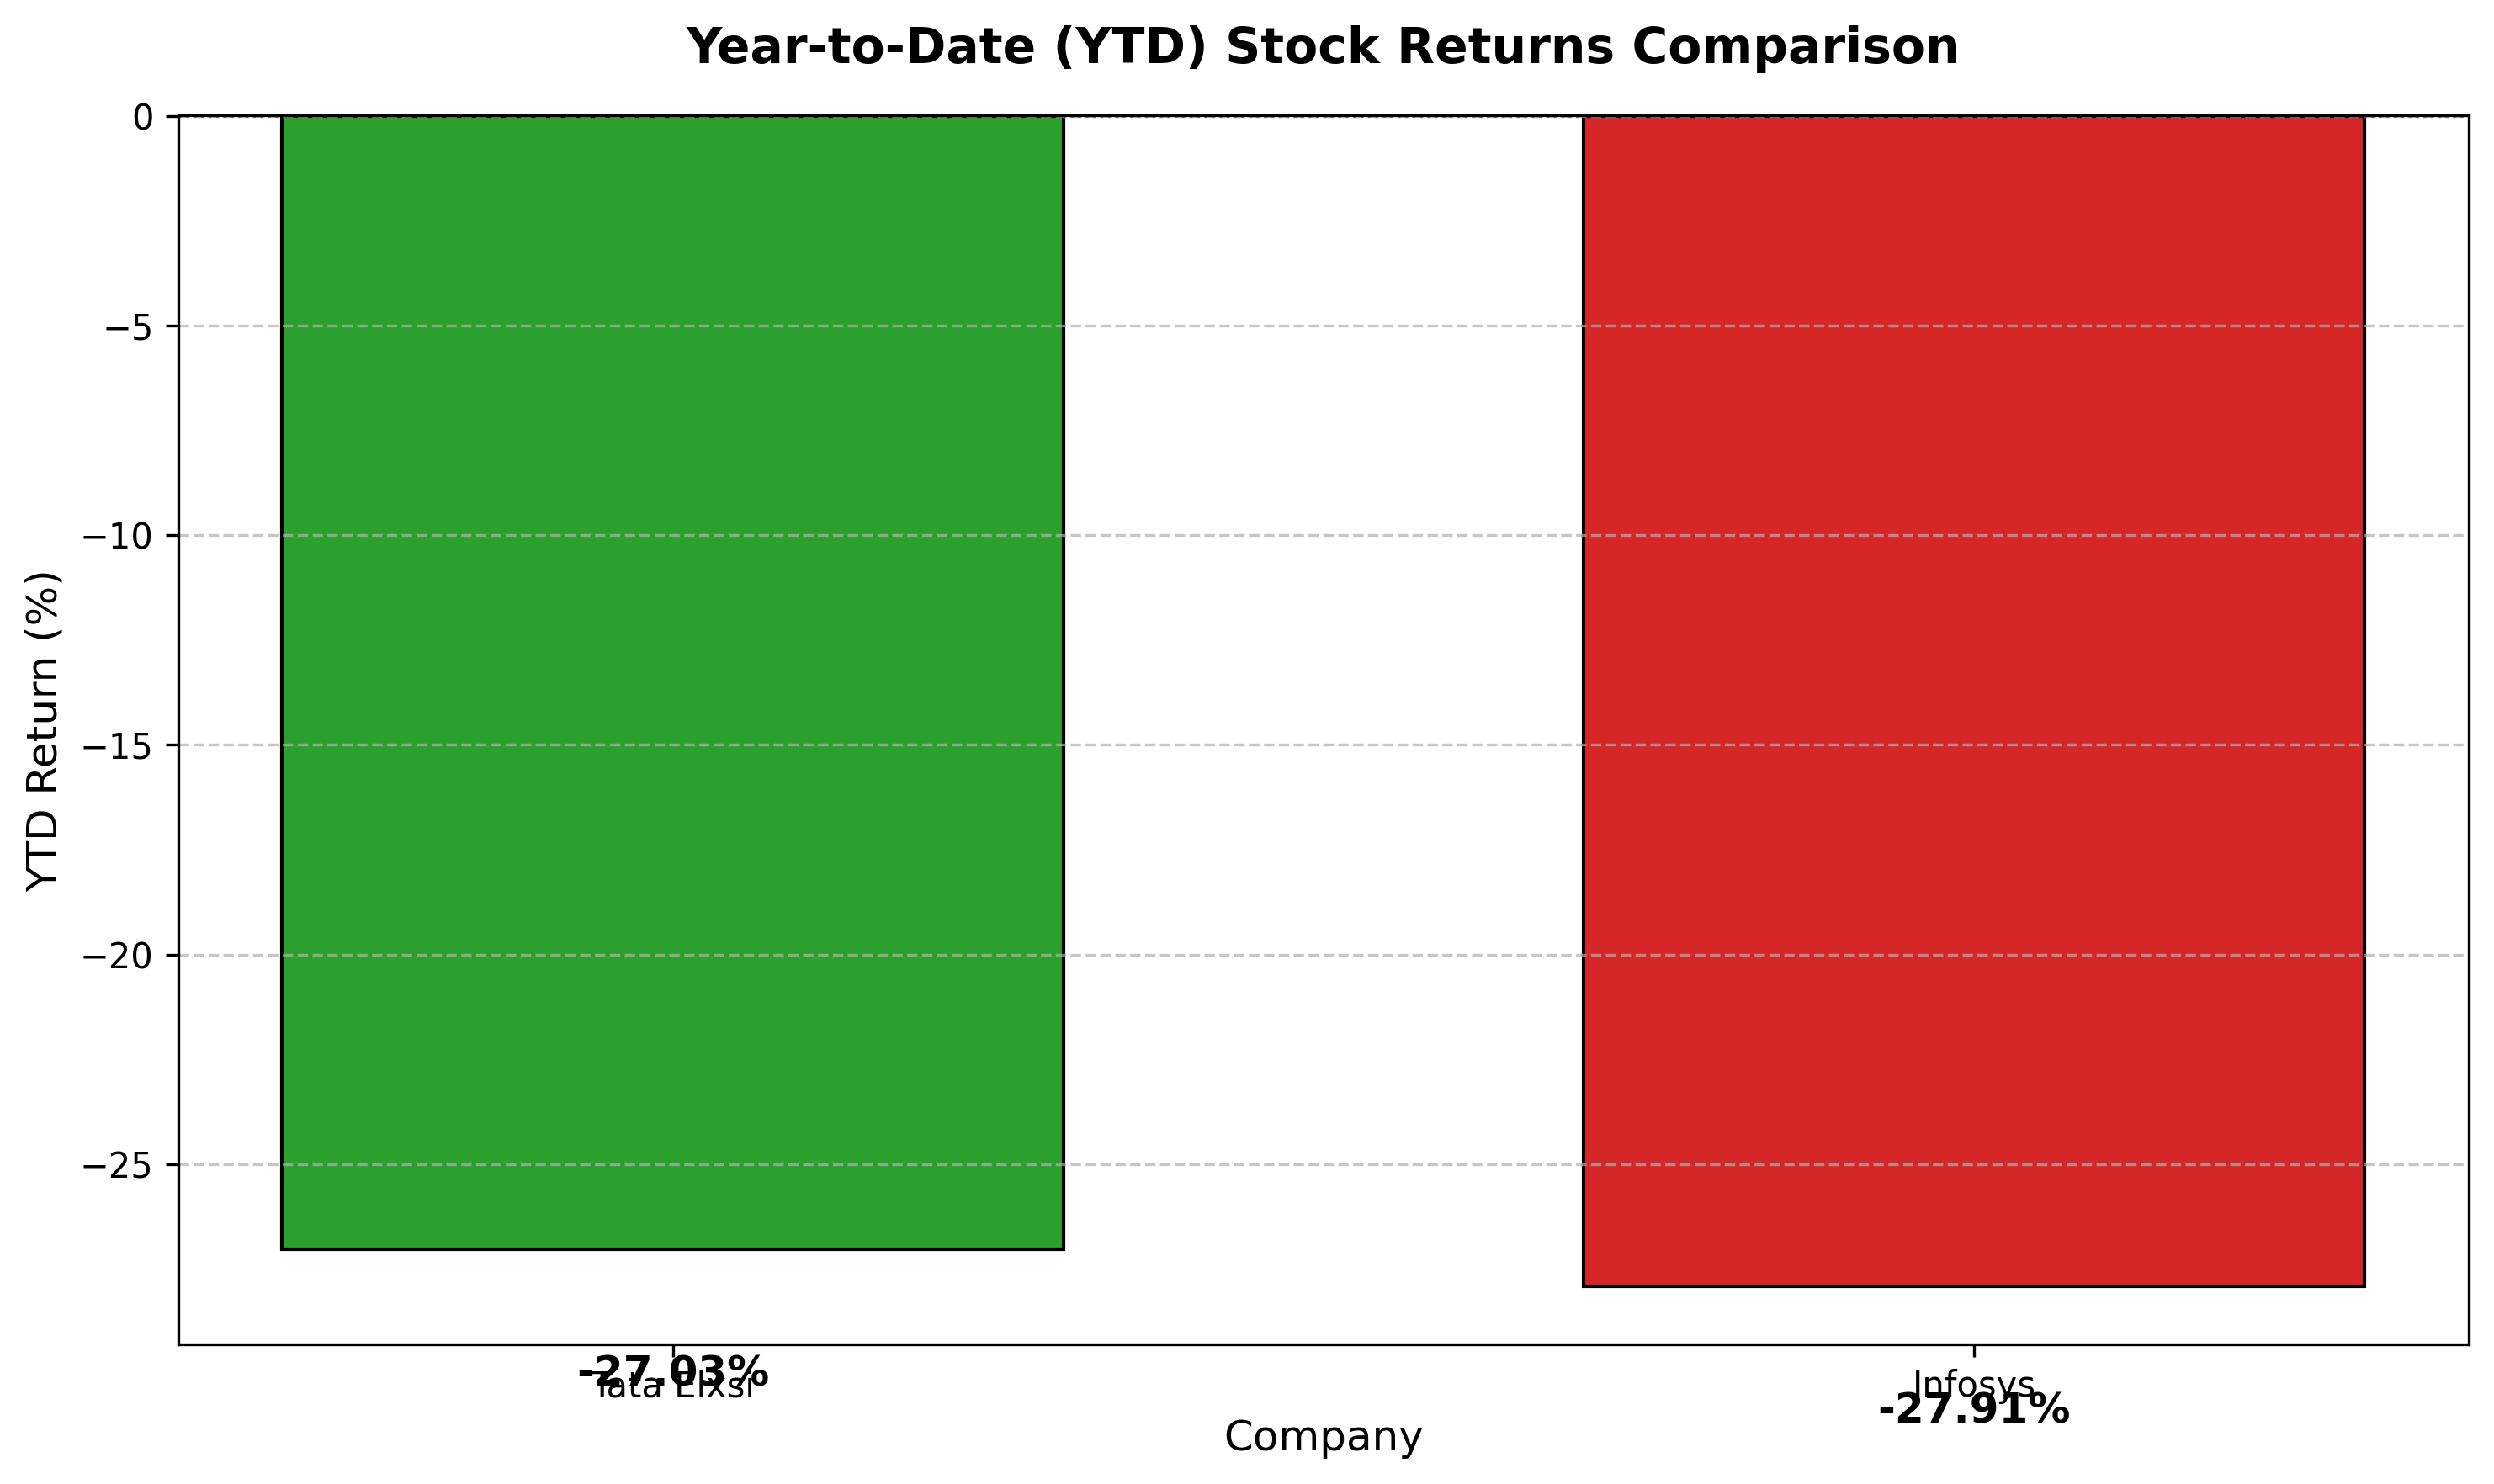

In [23]:

# ============================================================
# 8. DISPLAY THE GENERATED STOCK ANALYSIS FIGURE
# ============================================================

from IPython.display import display, Image

figure_path = os.path.join(
    "coding",
    "ytd_stock_gains.png"
)

if os.path.exists(figure_path):
    print("\nStock analysis figure generated successfully!")
    display(Image(filename=figure_path))
else:
    print("\nFigure not found. Please inspect the agent execution output.")
